# Model comparison

Roadmap step 4. How well do models predict when a group member breaks from their group's line, compared with the group-line baseline and the member's own record?

Setup (details in [docs](../docs/README.md)):

- **Target:** a position (For, Against or Abstention) different from the group's most common position without the member.
- **Given to every model:** the realised line of every group on the roll call. So these are predictions of who breaks from a known group line, not of how a roll call turns out.
- **Time split:** train January 2020 to June 2023, choose trees and epochs on July 2023 to July 2024, and **test on the 10th term** (16 July 2024 to October 2026).
- **Two kinds of roll call:** the member's group took the same line as most other groups, or not. These are the counterpart of the USA's bipartisan and party-opposed roll calls.

Predictions come from `run_model.py` and are read from `outputs/predictions.parquet`.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent))
from run_model import summarise

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
NEUTRAL = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})
LABELS = {"GUE_NGL": "The Left", "GREEN_EFA": "Greens/EFA", "SD": "S&D", "RENEW": "Renew", "EPP": "EPP",
          "ECR": "ECR", "PFE": "PfE", "ESN": "ESN"}
GROUP_ORDER = ["GREEN_EFA", "GUE_NGL", "SD", "RENEW", "EPP", "ECR", "PFE", "ESN"]
MODELS = {"group_line": "Group line", "training_rate": "Training rate", "own_past_rate": "Own past rate",
          "logistic": "Logistic regression", "boosting": "Gradient boosting", "gru_seed0": "GRU, seed 0",
          "gru_seed1": "GRU, seed 1", "gru_seed2": "GRU, seed 2", "boosting_with_split": "Boosting + split (after the vote)"}

predictions = pd.read_parquet(Path.cwd().parent / "outputs" / "predictions.parquet")
test = predictions[predictions["split"] == "test"].reset_index(drop=True)
print(f"Test: {len(test):,} positions on {test['vote_id'].nunique():,} roll calls by {test['member_id'].nunique():,} members; "
      f"defection rate {test['defected'].mean():.4f}")
print("Share of test positions where the group took the line of most other groups:", round(test["with_most_groups"].mean(), 3))

Test: 3,732,907 positions on 6,226 roll calls by 715 members; defection rate 0.0813
Share of test positions where the group took the line of most other groups: 0.629


## Test results

In [2]:
subsets = {"all positions": np.ones(len(test), bool), "group with most groups": test["with_most_groups"].to_numpy(),
           "group against most groups": ~test["with_most_groups"].to_numpy()}
tables = {}
for label, mask in subsets.items():
    part = test[mask]
    with warnings.catch_warnings():  # the against-most column is empty within the with-most subset
        warnings.simplefilter("ignore", RuntimeWarning)
        tables[label] = pd.DataFrame({MODELS[m]: summarise(part, part[f"p_{m}"].to_numpy()) for m in MODELS}).T
    tables[label].loc[:, "defection_rate"] = part["defected"].mean()
display(tables["all positions"].round(4))
for label in ["group with most groups", "group against most groups"]:
    print(label)
    display(tables[label][["line_accuracy", "defection_auc", "defection_average_precision", "defection_rate"]].round(4))

,line_accuracy,line_accuracy_against_most,defection_auc,defection_average_precision,defection_log_loss,defections_caught,flag_precision,defection_rate
Group line,0.9187,0.8886,0.5000,0.0813,1.1232,0.0000,0.0000,0.0813
Training rate,0.9187,0.8886,0.5000,0.0813,0.2820,0.0000,0.0000,0.0813
Own past rate,0.9186,0.8884,0.7260,0.2017,0.2592,0.0092,0.4610,0.0813
Logistic regression,0.9203,0.8919,0.7990,0.3248,0.2326,0.0999,0.5532,0.0813
Gradient boosting,0.9211,0.8935,0.8017,0.3315,0.2304,0.0995,0.5874,0.0813
"GRU, seed 0",0.9262,0.9005,0.8393,0.4247,0.2120,0.2171,0.6340,0.0813
"GRU, seed 1",0.9258,0.8996,0.8376,0.4186,0.2130,0.2023,0.6369,0.0813
"GRU, seed 2",0.9255,0.8995,0.8344,0.4153,0.2142,0.2113,0.6230,0.0813
Boosting + split (after the vote),0.9595,0.9477,0.9673,0.8266,0.1047,0.6204,0.8402,0.0813


group with most groups


,line_accuracy,defection_auc,defection_average_precision,defection_rate
Group line,0.9364,0.5000,0.0636,0.0636
Training rate,0.9364,0.5000,0.0636,0.0636
Own past rate,0.9364,0.7368,0.1891,0.0636
Logistic regression,0.9370,0.7950,0.2956,0.0636
Gradient boosting,0.9374,0.7997,0.2912,0.0636
"GRU, seed 0",0.9413,0.8393,0.3901,0.0636
"GRU, seed 1",0.9412,0.8401,0.3901,0.0636
"GRU, seed 2",0.9408,0.8376,0.3818,0.0636
Boosting + split (after the vote),0.9665,0.9658,0.7990,0.0636


group against most groups


,line_accuracy,defection_auc,defection_average_precision,defection_rate
Group line,0.8886,0.5000,0.1114,0.1114
Training rate,0.8886,0.5000,0.1114,0.1114
Own past rate,0.8884,0.6734,0.2101,0.1114
Logistic regression,0.8919,0.7815,0.3602,0.1114
Gradient boosting,0.8935,0.7837,0.3675,0.1114
"GRU, seed 0",0.9005,0.8229,0.4566,0.1114
"GRU, seed 1",0.8996,0.8178,0.4454,0.1114
"GRU, seed 2",0.8995,0.8149,0.4465,0.1114
Boosting + split (after the vote),0.9477,0.9668,0.8519,0.1114


**The 10th term** has 3.7 million positions on 6,226 roll calls by 715 members. 8.1% of positions break from the group line: 6.4% where the group took the line of most other groups and 11.1% where it didn't. 63% of test positions are of the first kind, fewer than in training (71% over the whole table).

- **Line accuracy barely moves, because defections are rare.** The group line alone is right on 91.9% of positions (88.9% where the group went against most groups). The best model, the GRU, reaches 92.6% (90.0%). At a 0.5 threshold it flags about 21% of defections, and 62% to 64% of its flags are right. Boosting flags 10%; the own past rate flags almost none.
- **Ranking defections is where the models differ.** Defection AUC rises from 0.726 for the member's own past rate to 0.799 for logistic regression, 0.802 for boosting and 0.834 to 0.839 for the three GRU seeds. Average precision, against a base rate of 0.081, rises from 0.202 to 0.325, 0.332 and 0.415 to 0.425.
- **The ladder is the same on both kinds of roll call.** Where the group went against most groups, defections are commoner and all models rank them slightly worse (GRU 0.815 to 0.823 against 0.838 to 0.840), but each step holds.
- **The after-the-vote reference** (how split the group was and what national colleagues did on the same roll call) reaches AUC 0.967 and average precision 0.827. Most of what separates defectors is how the rest of the delegation voted at the same moment, which no forecast can know. The vote explanation step found the same: members side with united national colleagues on 96% to 97% of conflicts.

## Are the steps larger than chance?

A two-way bootstrap: each draw resamples roll calls and members together, weighting each position by how often its roll call and its member were drawn. 200 draws. Differences in AUC and average precision between neighbouring models, over all positions and for each kind of roll call. Seeds of the GRU are compared singly with the one boosting model.

In [3]:
from sklearn.metrics import average_precision_score, roc_auc_score


class Ranked:
    """Scores sorted once, so each bootstrap draw only reweights: weighted AUC (ties counted half) and average precision."""

    def __init__(self, score, y):
        self.ascending = np.argsort(score, kind="mergesort")
        sorted_score = score[self.ascending]
        self.starts = np.flatnonzero(np.r_[True, sorted_score[1:] != sorted_score[:-1]])
        self.y_up = y[self.ascending]
        self.descending = self.ascending[::-1]
        self.y_down = y[self.descending]
        down_score = sorted_score[::-1]
        # Average precision steps at each distinct score, as scikit-learn does.
        self.down_ends = np.r_[np.flatnonzero(down_score[1:] != down_score[:-1]), len(down_score) - 1]

    def auc(self, w):
        ww = w[self.ascending]
        pos = np.add.reduceat(ww * self.y_up, self.starts)
        neg = np.add.reduceat(ww * (1 - self.y_up), self.starts)
        below = np.cumsum(neg) - neg
        return float((pos * (below + neg / 2)).sum() / (pos.sum() * neg.sum()))

    def ap(self, w):
        ww = w[self.descending]
        tp = np.cumsum(ww * self.y_down)[self.down_ends]
        fp = np.cumsum(ww * (1 - self.y_down))[self.down_ends]
        recall = tp / tp[-1]
        precision = tp / np.maximum(tp + fp, 1e-12)
        return float(np.sum(np.diff(np.r_[0, recall]) * precision))


y = test["defected"].to_numpy().astype(float)
ladder = ["own_past_rate", "logistic", "boosting", "gru_seed0", "gru_seed1", "gru_seed2"]
ranked = {(label, m): Ranked(test.loc[mask, f"p_{m}"].to_numpy(), y[mask]) for label, mask in subsets.items() for m in ladder}
check = ranked[("all positions", "boosting")]
ones = np.ones(len(test))
assert abs(check.auc(ones) - roc_auc_score(y, test["p_boosting"])) < 1e-6
assert abs(check.ap(ones) - average_precision_score(y, test["p_boosting"])) < 1e-6

rng = np.random.default_rng(0)
calls, call_index = np.unique(test["vote_id"], return_inverse=True)
people, person_index = np.unique(test["member_id"], return_inverse=True)
draws = []
for _ in range(200):
    w = (np.bincount(rng.integers(0, len(calls), len(calls)), minlength=len(calls))[call_index]
         * np.bincount(rng.integers(0, len(people), len(people)), minlength=len(people))[person_index]).astype(float)
    row = {}
    for label, mask in subsets.items():
        wm = w[mask]
        for m in ladder:
            row[(label, m, "auc")] = ranked[(label, m)].auc(wm)
            row[(label, m, "ap")] = ranked[(label, m)].ap(wm)
    draws.append(row)
draws = pd.DataFrame(draws)
steps = [("logistic", "own_past_rate"), ("boosting", "logistic")] + [(f"gru_seed{s}", "boosting") for s in range(3)]
rows_out = {}
for label in subsets:
    for better, worse in steps:
        for metric in ["auc", "ap"]:
            diff = draws[(label, better, metric)] - draws[(label, worse, metric)]
            rows_out[(label, f"{MODELS[better]} over {MODELS[worse]}", metric)] = diff.quantile([0.025, 0.5, 0.975]).to_numpy()
intervals = pd.DataFrame(rows_out, index=["2.5%", "median", "97.5%"]).T
display(intervals.round(4))

2.5%  \
all positions             Logistic regression over Own past rate     auc  0.0672   
                                                                     ap   0.1144   
                          Gradient boosting over Logistic regression auc  0.0004   
                                                                     ap   0.0006   
                          GRU, seed 0 over Gradient boosting         auc  0.0350   
                                                                     ap   0.0858   
                          GRU, seed 1 over Gradient boosting         auc  0.0337   
                                                                     ap   0.0801   
                          GRU, seed 2 over Gradient boosting         auc  0.0297   
                                                                     ap   0.0768   
group with most groups    Logistic regression over Own past rate     auc  0.0500   
                                                                     ap   0.0956   
                          Gradient boosting over Logistic regression auc  0.0010   
                                                                     ap  -0.0117   
                          GRU, seed 0 over Gradient boosting         auc  0.0357   
                                                                     ap   0.0880   
                          GRU, seed 1 over Gradient boosting         auc  0.0365   
                                                                     ap   0.0897   
                          GRU, seed 2 over Gradient boosting         auc  0.0336   
                                                                     ap   0.0811   
group against most groups Logistic regression over Own past rate     auc  0.0986   
                                                                     ap   0.1385   
                          Gradient boosting over Logistic regression auc -0.0010   
                                                                     ap  -0.0007   
                          GRU, seed 0 over Gradient boosting         auc  0.0356   
                                                                     ap   0.0804   
                          GRU, seed 1 over Gradient boosting         auc  0.0301   
                                                                     ap   0.0679   
                          GRU, seed 2 over Gradient boosting         auc  0.0266   
                                                                     ap   0.0691   

                                                                          median  \
all positions             Logistic regression over Own past rate     auc  0.0730   
                                                                     ap   0.1232   
                          Gradient boosting over Logistic regression auc  0.0025   
                                                                     ap   0.0063   
                          GRU, seed 0 over Gradient boosting         auc  0.0374   
                                                                     ap   0.0926   
                          GRU, seed 1 over Gradient boosting         auc  0.0359   
                                                                     ap   0.0872   
                          GRU, seed 2 over Gradient boosting         auc  0.0325   
                                                                     ap   0.0834   
group with most groups    Logistic regression over Own past rate     auc  0.0582   
                                                                     ap   0.1062   
                          Gradient boosting over Logistic regression auc  0.0048   
                                                                     ap  -0.0046   
                          GRU, seed 0 over Gradient boosting         auc  0.0394   
                                                                     ap   0.0984   
                          GRU, seed 1 over 

Intervals are 95% two-way bootstrap intervals (roll calls and members resampled together, 200 draws) for the difference between consecutive models on the test term.

- **Logistic regression over the own past rate:** clearly larger than chance everywhere (AUC +0.073 over all positions, +0.109 where the group went against most groups).
- **Boosting over logistic regression:** small. Over all positions the interval is just above zero (AUC +0.0025, from +0.0004 to +0.0053). Within either kind of roll call the AUC or average-precision interval includes zero, so a gain there isn't established.
- **Each GRU seed over boosting:** AUC +0.031 to +0.040 and average precision +0.078 to +0.099, with every interval well away from zero, in all three subsets.

The intervals hold the fitted models fixed: they don't include refit variation (seed, early stopping). The three GRU seeds differ by 0.005 in AUC, much less than their gain over boosting.

## Over time and by group

In [4]:
periods = predictions.assign(half=predictions["date"].dt.year + (predictions["date"].dt.month > 6) * 0.5)
by_half = periods.groupby("half").apply(lambda part: pd.Series({
    "positions": len(part), "defection_rate": part["defected"].mean(),
    **{MODELS[m]: roc_auc_score(part["defected"], part[f"p_{m}"]) for m in ["own_past_rate", "boosting", "gru_seed0"]}}),
    include_groups=False)
by_half.index = [f"{int(h)} {'H2' if h % 1 else 'H1'}" for h in by_half.index]
print("AUC by half-year (validation, then test):")
display(by_half.round(3))
by_group = test.groupby("group_code").apply(lambda part: pd.Series({
    "positions": len(part), "defection_rate": part["defected"].mean(),
    **{f"AUC {MODELS[m]}": roc_auc_score(part["defected"], part[f"p_{m}"]) for m in ["own_past_rate", "boosting", "gru_seed0"]},
    **{f"AP {MODELS[m]}": average_precision_score(part["defected"], part[f"p_{m}"]) for m in ["own_past_rate", "boosting", "gru_seed0"]}}),
    include_groups=False)
print("Test, by group:")
display(by_group.reindex([g for g in GROUP_ORDER if g in by_group.index]).rename(index=LABELS).round(3))

AUC by half-year (validation, then test):


,positions,defection_rate,Own past rate,Gradient boosting,"GRU, seed 0"
2023 H2,886562.0,0.095,0.710,0.823,0.851
2024 H1,844905.0,0.102,0.701,0.820,0.848
2024 H2,288866.0,0.099,0.729,0.799,0.830
2025 H1,799116.0,0.082,0.739,0.799,0.834
2025 H2,906860.0,0.079,0.721,0.816,0.855
2026 H1,1077997.0,0.082,0.722,0.796,0.832
2026 H2,660068.0,0.075,0.721,0.793,0.837


Test, by group:


,positions,defection_rate,AUC Own past rate,AUC Gradient boosting,"AUC GRU, seed 0",AP Own past rate,AP Gradient boosting,"AP GRU, seed 0"
group_code,,,,,,,,
Greens/EFA,295576.0,0.042,0.749,0.826,0.849,0.113,0.300,0.355
The Left,239482.0,0.079,0.691,0.771,0.807,0.177,0.299,0.371
S&D,732169.0,0.047,0.684,0.781,0.832,0.108,0.257,0.361
Renew,417159.0,0.058,0.712,0.785,0.828,0.136,0.281,0.368
EPP,1005221.0,0.075,0.718,0.809,0.844,0.190,0.332,0.436
ECR,438819.0,0.124,0.661,0.741,0.786,0.246,0.368,0.442
PfE,456967.0,0.151,0.629,0.731,0.793,0.234,0.356,0.451
ESN,147514.0,0.096,0.780,0.850,0.877,0.273,0.400,0.509


- **Over time:** no decay across the term change. GRU AUC is 0.848 to 0.851 on the validation half-years of the 9th term and 0.830 to 0.855 on the five half-years of the 10th; boosting falls slightly, from 0.82 to 0.79 to 0.80. The new groups in the 10th term (PfE, ESN) don't break the models, which don't use group identity.
- **By group:** the GRU ranks defections better than boosting in every group. AUC is lowest in PfE (0.793) and ECR (0.786), which also have the highest defection rates (15.1% and 12.4%), and highest in ESN (0.877) and Greens/EFA (0.849). Average precision depends on each group's base rate, so it shouldn't be compared across groups; within each group the GRU's gain over boosting is 0.05 to 0.11.
- These are single-seed figures (seed 0) without intervals; ESN has the fewest positions (148,000).

## First position of the day or later

Consecutive roll calls are usually seconds apart (median 15 seconds), often on the same text, so the GRU's "defected on the previous roll call" input mostly comes from minutes earlier. That is known before the next vote, so it isn't leakage, but it makes these one-roll-call-ahead predictions. A member's first position on a sitting day has only earlier days' outcomes behind it.

In [5]:
ordered = test.sort_values(["member_id", "timestamp", "vote_id"])
first_of_day = (ordered["member_id"] != ordered["member_id"].shift()) | (ordered["date"] != ordered["date"].shift())
test["first_of_day"] = first_of_day.reindex(test.index).to_numpy()
day_table = test.groupby("first_of_day").apply(lambda part: pd.Series({
    "positions": len(part), "defection_rate": part["defected"].mean(),
    **{f"AUC {MODELS[m]}": roc_auc_score(part["defected"], part[f"p_{m}"]) for m in ["own_past_rate", "logistic", "boosting", "gru_seed0"]},
    **{f"AP {MODELS[m]}": average_precision_score(part["defected"], part[f"p_{m}"]) for m in ["boosting", "gru_seed0"]}}),
    include_groups=False)
day_table.index = day_table.index.map({True: "first position of the day", False: "later positions"})
display(day_table.round(3))

,positions,defection_rate,AUC Own past rate,AUC Logistic regression,AUC Gradient boosting,"AUC GRU, seed 0",AP Gradient boosting,"AP GRU, seed 0"
first_of_day,,,,,,,,
later positions,3668006.0,0.081,0.726,0.801,0.803,0.841,0.335,0.429
first position of the day,64901.0,0.078,0.704,0.699,0.703,0.696,0.183,0.183


**The GRU's whole gain comes from earlier positions on the same sitting day.** On a member's first position of the day (65,000 positions, 1.7% of the test term), the GRU is no better than boosting: AUC 0.696 against 0.703, and average precision 0.183 for both. On later positions it leads by 0.038 in AUC and 0.094 in average precision.

- Boosting also gets whether the member defected on the previous roll call (`last_defected`), so what the GRU adds is more than the last outcome: probably the run of recent outcomes within the same block of votes, often amendments to the same text. This is an interpretation; the notebook doesn't isolate it.
- All models rank first positions of the day worse (own past rate 0.704, boosting 0.703). So the first position isn't only a cleaner test: those roll calls may differ in kind, for example opening votes of a session. The comparison between the GRU and boosting within that subset is the point, not the level.
- So the GRU's advantage is real for predicting the next roll call during a voting session, when earlier results of the same session are known. For predicting a member's positions before a session starts, it adds nothing over boosting.

## Calibration

Mean predicted probability against the observed defection rate, in ten bins of predicted probability, test term.

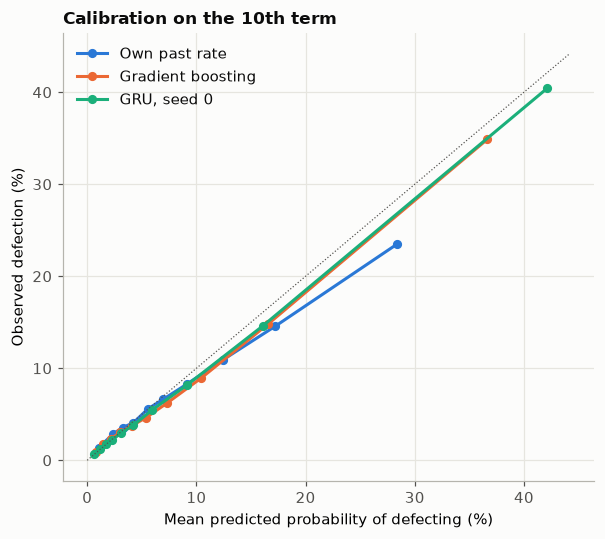

Mean prediction against observed rate: {'Own past rate': 0.0905, 'Gradient boosting': 0.0879, 'GRU, seed 0': 0.0864} observed 0.0813


In [6]:
fig, axis = plt.subplots(figsize=(5.6, 5))
for m, color in zip(["own_past_rate", "boosting", "gru_seed0"], SERIES):
    p = test[f"p_{m}"]
    bins = pd.qcut(p.rank(method="first"), 10, labels=False)
    table = test.groupby(bins).agg(predicted=(f"p_{m}", "mean"), observed=("defected", "mean"))
    axis.plot(table["predicted"] * 100, table["observed"] * 100, marker="o", markersize=5, color=color, label=MODELS[m])
limit = max(axis.get_xlim()[1], axis.get_ylim()[1])
axis.plot([0, limit], [0, limit], color=NEUTRAL, linewidth=0.8, linestyle=":")
axis.set_xlabel("Mean predicted probability of defecting (%)")
axis.set_ylabel("Observed defection (%)")
axis.set_title("Calibration on the 10th term")
axis.legend(loc="upper left")
fig.tight_layout()
plt.show()
print("Mean prediction against observed rate:",
      {MODELS[m]: round(float(test[f"p_{m}"].mean()), 4) for m in ["own_past_rate", "boosting", "gru_seed0"]},
      "observed", round(float(test["defected"].mean()), 4))

All three are close to the diagonal and slightly too high: mean predictions are 0.086 to 0.091 against 0.081 observed. Defection was more common in training and validation (8.5% and 9.8%) than in the 10th term, so this is a level shift from the time split, not a ranking problem. The own past rate is too high in its top bin (28% predicted, 23% observed): members with high past rates defected less in the new term. Boosting and the GRU follow the diagonal up to 35% to 40%.

## Compared with the USA

Both entities use the same ladder and the same kind of split. The definitions differ: the USA predicts Yea or Nay against the party majority in a two-party chamber; here three positions against a group plurality in a multi-party chamber, on two terms instead of decades. So levels are comparable only loosely; the order of the ladder is the comparison.

In [7]:
usa = pd.DataFrame({
    "USA AUC": [0.500, 0.773, 0.831, 0.850, "0.854 to 0.858"],
    "USA average precision": [0.064, 0.270, 0.362, 0.379, "0.401 to 0.409"],
}, index=["Group or party line", "Own past rate", "Logistic regression", "Gradient boosting", "GRU, single seeds"])
main = tables["all positions"]
gru = [main.loc[MODELS[f"gru_seed{s}"]] for s in range(3)]
usa["European Parliament AUC"] = [main.loc["Group line", "defection_auc"], main.loc["Own past rate", "defection_auc"],
                                  main.loc["Logistic regression", "defection_auc"], main.loc["Gradient boosting", "defection_auc"],
                                  f"{min(g['defection_auc'] for g in gru):.3f} to {max(g['defection_auc'] for g in gru):.3f}"]
usa["European Parliament average precision"] = [
    main.loc["Group line", "defection_average_precision"], main.loc["Own past rate", "defection_average_precision"],
    main.loc["Logistic regression", "defection_average_precision"], main.loc["Gradient boosting", "defection_average_precision"],
    f"{min(g['defection_average_precision'] for g in gru):.3f} to {max(g['defection_average_precision'] for g in gru):.3f}"]
display(usa.map(lambda v: round(v, 3) if isinstance(v, float) else v))
print("USA figures: usa/pipeline/vote_prediction/docs/README.md (test 2015 to 2024).")

,USA AUC,USA average precision,European Parliament AUC,European Parliament average precision
Group or party line,0.5,0.064,0.5,0.081
Own past rate,0.773,0.27,0.726,0.202
Logistic regression,0.831,0.362,0.799,0.325
Gradient boosting,0.85,0.379,0.802,0.332
"GRU, single seeds",0.854 to 0.858,0.401 to 0.409,0.834 to 0.839,0.415 to 0.425


USA figures: usa/pipeline/vote_prediction/docs/README.md (test 2015 to 2024).


- **Same order of models:** own past rate, then logistic regression, then boosting, then the GRU, in both entities.
- **Different size of the GRU's gain:** in the USA the GRU adds only 0.004 to 0.008 AUC over boosting; here 0.031 to 0.040. The previous check shows the European Parliament gain comes from earlier positions on the same day. Many European Parliament roll calls come in quick blocks (median 15 seconds apart) on amendments to the same text. Whether the USA gain has the same source wasn't checked there.
- **Lower levels here for the feature models** (boosting 0.802 against 0.850). The targets differ (three positions against a leave-one-out group plurality, against Yea or Nay against the party majority), as do base rates (8.1% against 6.4%) and periods, so this isn't evidence that European Parliament defections are harder to predict.

## Summary

- Given every group's realised line, the GRU ranks who will break from their group's line best on the 10th term: AUC 0.834 to 0.839 and average precision 0.415 to 0.425, against 0.802 and 0.332 for boosting and 0.726 and 0.202 for the member's own past rate. Each step except boosting over logistic regression is clearly larger than chance in a two-way bootstrap.
- Line accuracy improves little (91.9% for the group line, 92.6% for the GRU), because defections are 8% of positions and most aren't predictable from the member's record.
- The GRU's gain over boosting comes entirely from earlier positions on the same sitting day. On a member's first position of the day it is no better than boosting.
- Knowing how the delegation voted on the same roll call raises AUC to 0.967: the main source of defection is the national delegation, as in the explanation step, and it isn't available before the vote.
- Limits: all models are conditional on the realised group lines, standing in for voting lists published before votes; the test term is one term of new groups; intervals don't include refit variation; and these are associations in a selected sample of roll calls.